# Intent Classifier Chatbot SIKA: LPK Star Skills Innovations
**Asah 2026 · Capstone A26-CS127 · Gen AI**

Notebook ini membangun **model klasifikasi intent buatan sendiri (dari nol, tanpa model pretrained)** untuk chatbot SIKA.
Model dipakai untuk mengarahkan pertanyaan pengunjung: dijawab RAG, ditolak (di luar konteks), atau dialihkan ke admin.

**Alur:** muat data, eksplorasi, preprocessing, bandingkan model (metrik sama), tuning, evaluasi data uji, analisis confidence, lalu simpan model.

> **Sumber data:** `intent_dataset.csv`: data **dummy** yang ditulis manual tim (kolom `source = dummy-manual`) berdasarkan profil resmi LPK. Keterbatasan: jumlah kecil dan gaya bahasa masih seragam, jadi skor bisa lebih optimis daripada kondisi nyata.
> **Library:** pandas, scikit-learn, matplotlib, joblib.

In [1]:
import re, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score)

RANDOM_STATE = 42

## 1. Muat data & eksplorasi

In [2]:
df = pd.read_csv('intent_dataset.csv')
print(df.shape)
df.head()

(224, 4)


,id,text,intent,source
0,D001,Program pelatihan apa saja yang ada di LPK Sta...,tanya_program,dummy-manual
1,D002,Ada jurusan apa aja di sini?,tanya_program,dummy-manual
2,D003,Boleh tahu daftar pelatihan yang tersedia?,tanya_program,dummy-manual
3,D004,LPK ini buka pelatihan apa saja ya?,tanya_program,dummy-manual
4,D005,Apakah ada pelatihan teknik pendingin AC?,tanya_program,dummy-manual


intent
tanya_program                 28
tanya_syarat_pendaftaran      28
tanya_jadwal_biaya            28
tanya_fasilitas_sertifikat    28
minta_rekomendasi_jurusan     28
tanya_kontak_lokasi           28
sapaan_penutup                28
di_luar_konteks               28
Name: count, dtype: int64

Rasio kelas terbesar / terkecil: 1.0


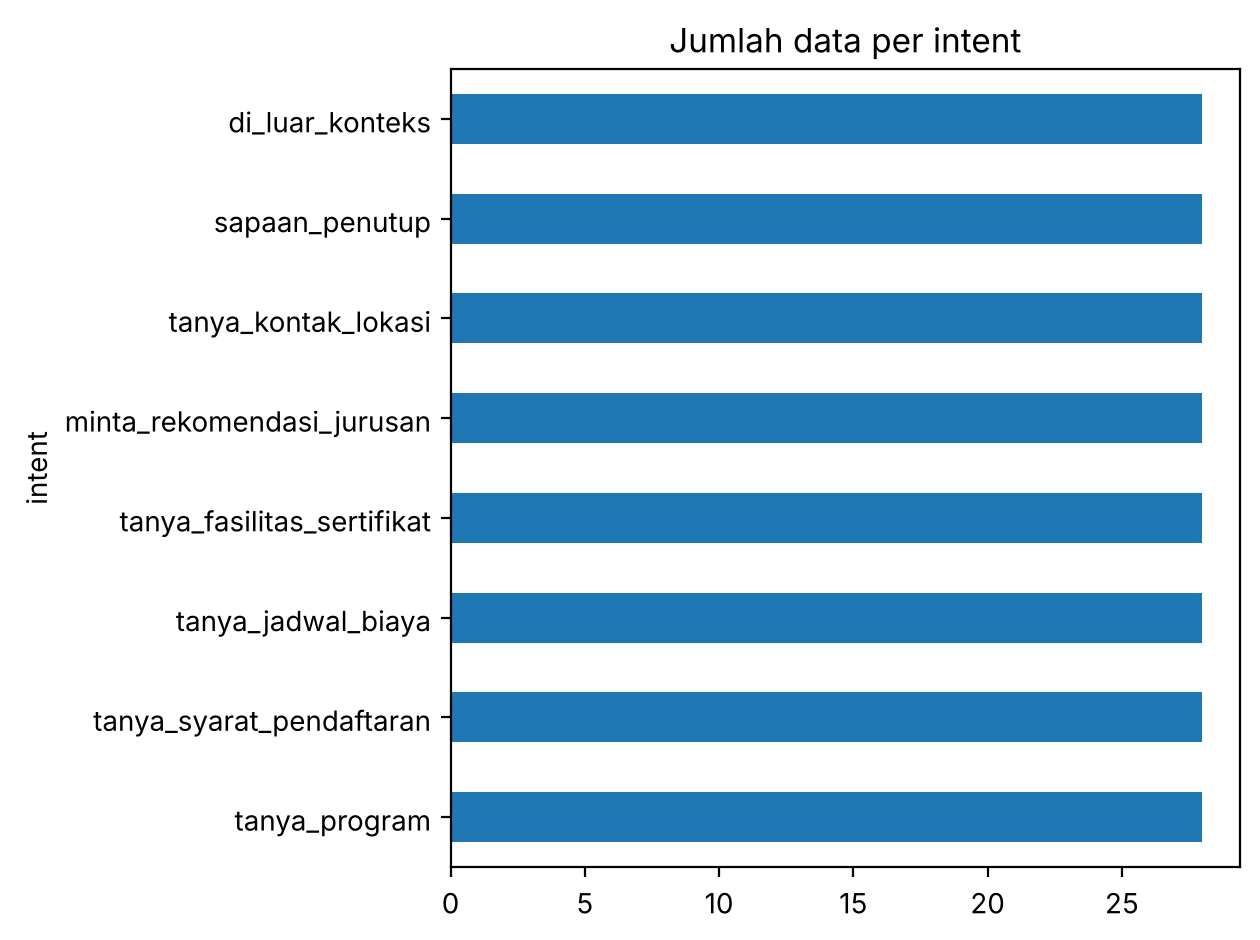

In [3]:
counts = df['intent'].value_counts()
print(counts)
print('\nRasio kelas terbesar / terkecil:', counts.max() / counts.min())
counts.plot(kind='barh', title='Jumlah data per intent'); plt.tight_layout(); plt.show()

**Keseimbangan kelas:** setiap intent punya jumlah data sama, jadi tidak perlu oversampling/undersampling. (Kalau nanti data ditambah dan tidak seimbang, aktifkan `class_weight='balanced'`, sudah diuji di bagian tuning.)

## 2. Preprocessing teks
Langkah: huruf kecil, hapus tanda baca, normalisasi singkatan/kata gaul umum, lalu rapikan spasi. Kata sapaan seperti "kak" sengaja **tidak** dibuang karena menjadi petunjuk intent `sapaan_penutup`. TF-IDF dilakukan **di dalam pipeline** supaya tidak terjadi kebocoran data (vocabulary hanya dipelajari dari data latih).

In [4]:
SLANG = {'nggak':'tidak','gak':'tidak','ga':'tidak','tdk':'tidak','aja':'saja','yg':'yang','dgn':'dengan',
         'dmn':'dimana','dimana':'di mana','kpn':'kapan','brp':'berapa','wa':'whatsapp','min':'admin',
         'thanks':'terima kasih','makasih':'terima kasih'}

def preprocess(text):
    t = str(text).lower()
    t = re.sub(r'[^a-z0-9\s]', ' ', t)
    t = ' '.join(SLANG.get(w, w) for w in t.split())
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['text'].apply(preprocess)
df[['text','clean']].sample(5, random_state=1)

,text,clean
85,Apakah sertifikatnya dari BNSP?,apakah sertifikatnya dari bnsp
34,Apakah harus punya KTP Sidoarjo?,apakah harus punya ktp sidoarjo
67,Gratis itu dibiayai siapa?,gratis itu dibiayai siapa
102,Sertifikat BNSP berlaku berapa lama?,sertifikat bnsp berlaku berapa lama
69,Ada biaya ujian sertifikasi BNSP nggak?,ada biaya ujian sertifikasi bnsp tidak


## 3. Pembagian data latih / uji
Stratified 80/20. Data uji **tidak disentuh** sampai evaluasi akhir.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['intent'], test_size=0.2, stratify=df['intent'], random_state=RANDOM_STATE)
print('Train:', len(X_train), '| Test:', len(X_test))

Train: 179 | Test: 45


## 4. Perbandingan model (metrik yang sama)
Beberapa model dan konfigurasi fitur (TF-IDF kata, karakter n-gram, gabungan) dibandingkan dengan **5-fold stratified CV × 3 pengulangan pada data latih**, metrik sama: macro-F1 dan akurasi. Semua dilatih dari nol. Karakter n-gram membantu karena kalimat pendek, ada salah ketik, dan bahasa campur santai/formal.

In [6]:
def word_tfidf(): return TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)
def char_tfidf(): return TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), sublinear_tf=True)
def both_tfidf(): return FeatureUnion([('word', word_tfidf()), ('char', char_tfidf())])

models = {}
for fname, ff in [('kata', word_tfidf), ('karakter', char_tfidf), ('kata+karakter', both_tfidf)]:
    models[f'TF-IDF {fname} + Logistic Regression'] = Pipeline([('tfidf', ff()), ('clf', LogisticRegression(C=10, max_iter=3000, random_state=RANDOM_STATE))])
    models[f'TF-IDF {fname} + Linear SVM'] = Pipeline([('tfidf', ff()), ('clf', LinearSVC(random_state=RANDOM_STATE))])
models['TF-IDF kata + Multinomial NB'] = Pipeline([('tfidf', word_tfidf()), ('clf', MultinomialNB())])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['f1_macro','accuracy'])
    rows.append({'Model': name, 'CV macro-F1': r['test_f1_macro'].mean(), 'Std F1': r['test_f1_macro'].std(),
                 'CV akurasi': r['test_accuracy'].mean()})
cmp = pd.DataFrame(rows).sort_values('CV macro-F1', ascending=False).reset_index(drop=True)
cmp.round(4)

,Model,CV macro-F1,Std F1,CV akurasi
0,TF-IDF kata+karakter + Linear SVM,0.7184,0.0796,0.7263
1,TF-IDF karakter + Linear SVM,0.7148,0.0622,0.7226
2,TF-IDF kata+karakter + Logistic Regression,0.7068,0.0790,0.7170
3,TF-IDF karakter + Logistic Regression,0.6940,0.0737,0.7038
4,TF-IDF kata + Linear SVM,0.6656,0.0889,0.6779
5,TF-IDF kata + Logistic Regression,0.6604,0.0884,0.6723
6,TF-IDF kata + Multinomial NB,0.6443,0.0778,0.6556


**Tabel perbandingan di atas dipakai untuk README.** Tuliskan alasan pemilihan model terbaik berdasarkan macro-F1 CV, kestabilan (std), dan kemampuan memberi probabilitas (penting untuk aturan alih ke admin).

## 5. Tuning hyperparameter (Side Quest)
GridSearchCV pada Logistic Regression dengan fitur kata+karakter. Dipilih Logistic Regression karena bisa memberi **probabilitas** (dibutuhkan untuk aturan alih ke admin), selisihnya dengan Linear SVM kecil. Dibandingkan juga pengaruh `class_weight`, nilai C, dan rentang n-gram karakter.

In [7]:
base = Pipeline([('tfidf', both_tfidf()),
                 ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])
grid = {
    'tfidf__char__ngram_range': [(2,4), (2,5), (3,5)],
    'clf__C': [1, 5, 10, 50, 100],
    'clf__class_weight': [None, 'balanced'],
}
gs = GridSearchCV(base, grid, cv=cv, scoring='f1_macro', n_jobs=-1)
gs.fit(X_train, y_train)
print('Parameter terbaik :', gs.best_params_)
print('CV macro-F1 terbaik:', round(gs.best_score_, 4))
base_score = cmp.loc[cmp['Model']=='TF-IDF kata+karakter + Logistic Regression','CV macro-F1'].iloc[0]
print('CV macro-F1 sebelum tuning:', round(base_score, 4), '| perubahan:', round(gs.best_score_-base_score, 4))

Parameter terbaik : {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__char__ngram_range': (2, 4)}
CV macro-F1 terbaik: 0.7203
CV macro-F1 sebelum tuning: 0.7068 | perubahan: 0.0136


## 6. Evaluasi akhir pada data uji
Model terbaik hasil tuning dinilai **sekali** pada data uji yang tidak pernah dipakai untuk latih/tuning.

In [8]:
best = gs.best_estimator_
y_pred = best.predict(X_test)
print('Akurasi  :', round(accuracy_score(y_test, y_pred), 4))
print('Macro-F1 :', round(f1_score(y_test, y_pred, average='macro'), 4))
print()
print(classification_report(y_test, y_pred, digits=3))

Akurasi  : 0.7333
Macro-F1 : 0.7367

                            precision    recall  f1-score   support

           di_luar_konteks      1.000     0.600     0.750         5
 minta_rekomendasi_jurusan      0.556     1.000     0.714         5
            sapaan_penutup      1.000     0.833     0.909         6
tanya_fasilitas_sertifikat      0.667     0.333     0.444         6
        tanya_jadwal_biaya      0.833     0.833     0.833         6
       tanya_kontak_lokasi      0.800     0.800     0.800         5
             tanya_program      0.444     0.667     0.533         6
  tanya_syarat_pendaftaran      1.000     0.833     0.909         6

                  accuracy                          0.733        45
                 macro avg      0.787     0.738     0.737        45
              weighted avg      0.788     0.733     0.735        45



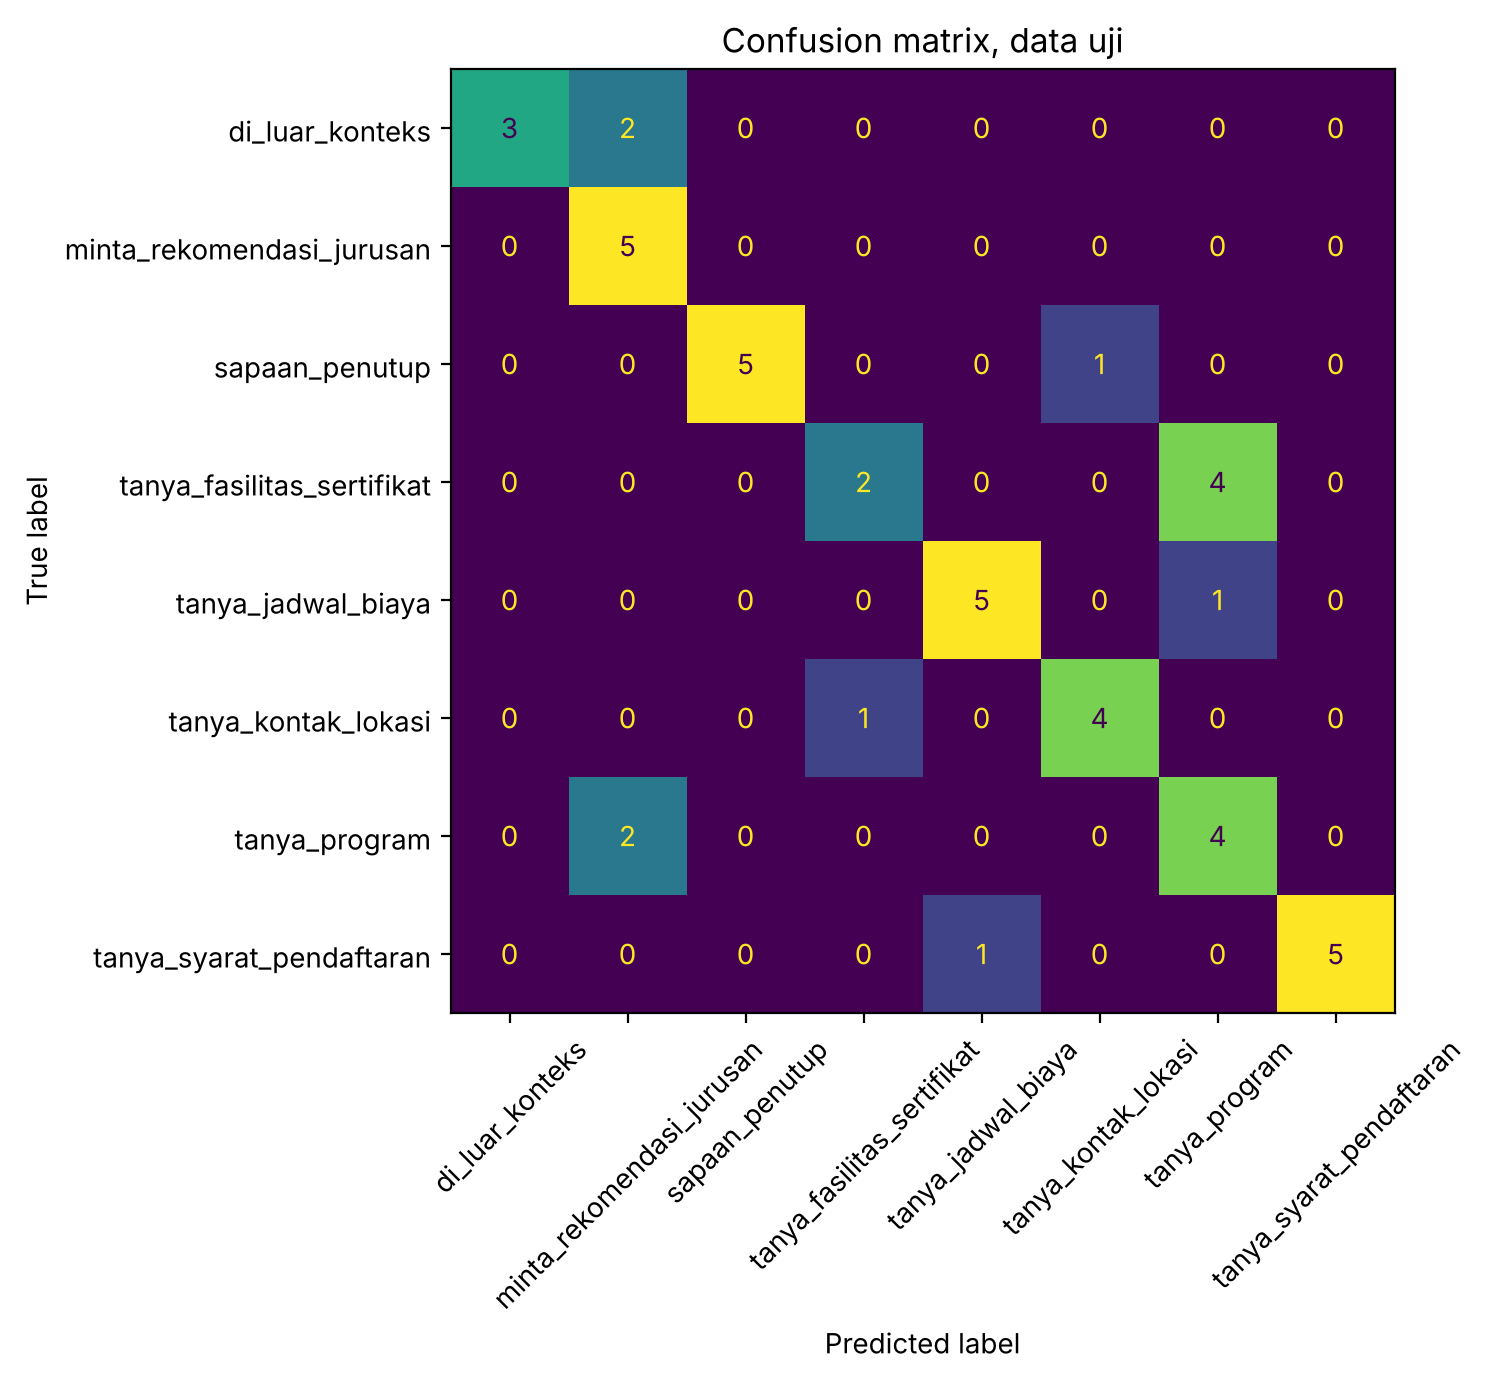

In [9]:
fig, ax = plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=45, colorbar=False)
plt.title('Confusion matrix, data uji'); plt.tight_layout(); plt.show()

### Analisis kesalahan
Kalimat yang salah diprediksi, dipakai untuk memperbaiki dataset (tambah variasi kalimat pada intent yang sering tertukar).

In [10]:
err = pd.DataFrame({'text': df.loc[X_test.index,'text'], 'asli': y_test, 'prediksi': y_pred})
err[err['asli'] != err['prediksi']]

,text,asli,prediksi
214,Obat sakit kepala yang bagus apa?,di_luar_konteks,minta_rekomendasi_jurusan
98,Instruktur di sini lulusan mana dan berpengala...,tanya_fasilitas_sertifikat,tanya_program
26,Apakah program Digital Marketing cocok untuk p...,tanya_program,minta_rekomendasi_jurusan
44,Seleksinya tes tertulis atau wawancara?,tanya_syarat_pendaftaran,tanya_jadwal_biaya
104,fasilitasnya apa aja sih kak,tanya_fasilitas_sertifikat,tanya_program
175,"Permisi, mau tanya",sapaan_penutup,tanya_kontak_lokasi
19,Jurusan apa yang berkaitan dengan administrasi?,tanya_program,minta_rekomendasi_jurusan
164,Apakah ada layanan telepon?,tanya_kontak_lokasi,tanya_fasilitas_sertifikat
62,Pelatihan teknisi motor injeksi mulai tanggal ...,tanya_jadwal_biaya,tanya_program
111,Ada pelatihan membuat CV dan wawancara kerja?,tanya_fasilitas_sertifikat,tanya_program


## 7. Confidence & aturan alih ke admin
Chatbot tidak boleh menebak. Jika **confidence tertinggi < ambang batas**, pertanyaan dialihkan ke admin (WhatsApp). Ambang dipilih dari data uji dengan menguji pertanyaan *di luar sebaran data latih*.

Di bawah, ambang diuji pada dua hal: (a) berapa persen data uji normal yang tetap dijawab otomatis, dan (b) berapa persen kalimat asing/ambigu yang berhasil dialihkan.

In [11]:
proba = best.predict_proba(X_test)
conf = proba.max(axis=1)

ambiguous = [  # pertanyaan dalam topik tapi tidak ada di KB / ambigu, contoh uji manual
    'Apakah ada beasiswa lanjutan setelah lulus?', 'Bisa cicil biaya seragam?', 'Apakah anak saya boleh ikut?',
    'Apakah pelatihan ini bisa online?', 'Ada diskon untuk peserta kedua?', 'Mau tanya soal asrama',
    'Apakah ada kelas weekend?', 'Bagaimana kalau saya disabilitas?', 'Boleh bawa laptop sendiri?', 'Apakah ada parkir?']
conf_amb = best.predict_proba([preprocess(t) for t in ambiguous]).max(axis=1)

rows = []
for th in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    rows.append({'ambang': th,
                 '% data uji dijawab otomatis': round((conf >= th).mean()*100, 1),
                 '% pertanyaan ambigu dialihkan ke admin': round((conf_amb < th).mean()*100, 1)})
pd.DataFrame(rows)

,ambang,% data uji dijawab otomatis,% pertanyaan ambigu dialihkan ke admin
0,0.10,100.0,0.0
1,0.15,97.8,0.0
2,0.20,75.6,20.0
3,0.25,60.0,50.0
4,0.30,37.8,80.0
5,0.40,11.1,100.0


**Perhatikan skala:** dengan 8 kelas, data kecil, dan regularisasi kuat (`C` kecil), probabilitas Logistic Regression cenderung rendah dan datar, sehingga ambang yang cocok jauh di bawah 0.5. Pilih ambang yang menjaga sebagian besar data normal tetap otomatis, tetapi mengalihkan mayoritas pertanyaan ambigu. Kalau data sudah bertambah, pertimbangkan kalibrasi probabilitas (`CalibratedClassifierCV`). Cantumkan tabel ini di README sebagai dasar pemilihan ambang. **Catatan:** daftar `ambiguous` di atas hanya 10 contoh, perbanyak dengan pertanyaan nyata dari LPK saat uji coba.

## 8. Fungsi routing (siap dipakai FastAPI)

In [12]:
CONF_THRESHOLD = 0.25   # sesuaikan berdasarkan tabel bagian 7

def route(question):
    q = preprocess(question)
    if not q:
        return {'intent': None, 'confidence': 0.0, 'action': 'invalid_input'}
    p = best.predict_proba([q])[0]
    intent = best.classes_[p.argmax()]; conf = float(p.max())
    if conf < CONF_THRESHOLD:
        action = 'handoff_admin'
    elif intent == 'di_luar_konteks':
        action = 'refuse_politely'
    elif intent == 'minta_rekomendasi_jurusan':
        action = 'redirect_quiz'
    elif intent == 'tanya_kontak_lokasi':
        action = 'show_contact_whatsapp'
    elif intent == 'sapaan_penutup':
        action = 'greet'
    else:
        action = 'answer_with_rag'
    return {'intent': intent, 'confidence': round(conf, 3), 'action': action}

for q in ['Syarat daftarnya apa saja?', 'Cocoknya aku ambil jurusan apa?', 'Siapa presiden Indonesia?',
          'Alamat lpk dimana', 'Apakah ada kelas weekend?', '', 'makasih kak']:
    print(repr(q), ':', route(q))

'Syarat daftarnya apa saja?' : {'intent': 'tanya_syarat_pendaftaran', 'confidence': 0.543, 'action': 'answer_with_rag'}
'Cocoknya aku ambil jurusan apa?' : {'intent': 'minta_rekomendasi_jurusan', 'confidence': 0.722, 'action': 'redirect_quiz'}
'Siapa presiden Indonesia?' : {'intent': 'di_luar_konteks', 'confidence': 0.433, 'action': 'refuse_politely'}
'Alamat lpk dimana' : {'intent': 'tanya_kontak_lokasi', 'confidence': 0.57, 'action': 'show_contact_whatsapp'}
'Apakah ada kelas weekend?' : {'intent': 'tanya_program', 'confidence': 0.223, 'action': 'handoff_admin'}
'' : {'intent': None, 'confidence': 0.0, 'action': 'invalid_input'}
'makasih kak' : {'intent': 'sapaan_penutup', 'confidence': 0.734, 'action': 'greet'}


## 9. Simpan model

In [13]:
joblib.dump(best, 'intent_classifier.joblib')
print('Model tersimpan: intent_classifier.joblib')

Model tersimpan: intent_classifier.joblib


## Catatan untuk README
- **Masalah:** pengunjung LPK mengajukan pertanyaan berulang; chatbot perlu tahu jenis pertanyaan agar dijawab, ditolak, atau dialihkan.
- **Sumber data:** dataset dummy buatan tim (`intent_dataset.csv`), berdasarkan profil resmi LPK.
- **Preprocessing:** lowercase, hapus tanda baca, normalisasi kata gaul, TF-IDF (unigram sampai trigram) di dalam pipeline.
- **Perbandingan model:** tabel bagian 4 (Logistic Regression vs Linear SVM vs Multinomial NB) + tuning bagian 5.
- **Evaluasi:** data uji terpisah, macro-F1, confusion matrix, analisis kesalahan.
- **Keterbatasan:** data kecil dan dummy; skor kemungkinan lebih tinggi dari kondisi nyata; perlu diuji dengan pertanyaan pengunjung asli.